# Tabular 02 · Exploratory analysis and the ECD thresholds

**Objective:** describe the grades and features, show how strongly grade tracks endothelial cell density (ECD), and why the project asks what explains grading **beyond** ECD.

**Derived from:** `notebooks/03_eda.ipynb`, the feature-role audit in `notebooks/02_data_cleaning.ipynb` and the candidate audit in `notebooks/04_feature_preparation.ipynb`, with the Konan redundancy check from `FINDINGS.md` §7 and the threshold description from `notebooks/images/08_missing_information.ipynb` §10.
**Cohort:** K1, the 1,036 labelled tissues. **Runtime:** a few seconds.

> **Correction to notebook 03:** it tested a wrong ECD rule (B 2000–2500, A 2500–3000, A+ above 3000), which matched the recorded grades for only about 30% of tissues (30% of those it could grade, 28% of all tissues with ECD). The eye bank's rule is **below 2250 → B, 2250 to below 2500 → A, 2500 and above → A+**, used from notebook 08 onward. Both are compared in Section 6. Repeated boxplots and printouts from notebook 03 were removed.

Set up paths and load the labelled dataset.

In [1]:
import sys
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import cleaned_setup as cs
import modeling_setup as ms

labelled = ms.load_labelled_data()
labelled["Year"] = labelled["Tissue_ID"].str.extract(r"NEB-\s*(\d{4})")[0].astype("Int64")
grades = labelled[ms.TARGET]
print("Labelled tissues:", len(labelled))

Labelled tissues: 1036


## 1. The target: three imbalanced grades

Macro F1 and balanced accuracy are reported alongside accuracy throughout, because grade B is the smallest class and the most important one to detect.

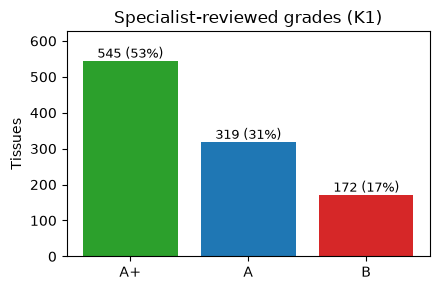

In [2]:
counts = grades.value_counts().reindex(cs.CLASSES)
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(counts.index, counts.values, color=["tab:green", "tab:blue", "tab:red"])
for i, v in enumerate(counts.values):
    ax.annotate(f"{v} ({v / len(grades):.0%})", (i, v), ha="center", va="bottom", fontsize=9)
ax.set(title="Specialist-reviewed grades (K1)", ylabel="Tissues", ylim=(0, counts.max() * 1.15))
plt.tight_layout()
plt.show()

## 2. How the 24 features were selected

The cleaned file has 116 columns. Selection happened in two steps. First, notebook 02 assigned every column a **role**, and only measurements and findings available when the specialist grades the tissue became candidates. Then notebook 04 dropped candidates that were too sparse to learn from.

| Role (notebook 02) | Examples | Used as feature? | Why |
|---|---|---|---|
| Target | `Tissue_Grade_Clean` | — | What is predicted |
| Leakage / downstream | Suitability, outcome, requested grade, surgery, `Additional_Findings` (quotes release-form grades) | **No** | Recorded after, or because of, the grading decision |
| Identifiers / metadata | Tissue ID, serial, file names, dataset part | **No** | Carry no clinical information; serials are used only to infer donors |
| Raw source text | `Stroma_Findings`, `Stroma_Severity`, `Tissue_Grade`, … | **No** (parsed instead) | Replaced by structured flags (Tabular 01) |
| Secondary / contextual | Form ECD, recipient age, graft and bed size, previous grafts | **No** | Form ECD duplicates the Konan ECD; the others describe the recipient or surgery, not the tissue |
| Konan morphology | ECD, CV, HEX, SD, cell count, area | **Yes (6)** | Endothelial evidence the specialist uses |
| Structured slit-lamp findings | 13 flags + categorical details | **Yes (18 of 24 candidates)** | Slit-lamp evidence the specialist uses |

The cleaned file's 116 columns, grouped by these roles:

In [3]:
full = pd.read_excel(ms.DATA_PATH)
LEAKAGE = ["Overall_Donor_Quality", "Transplant_Suitability", "Suitability_Reason", "Tissue_Outcome", "Recipient_Age",
           "Recipient_Eye", "Recipient_Indication", "Request_Indication", "Primary_Procedure", "Secondary_Procedures",
           "Surgery_Date", "Requested_Grade", "Planned_Procedure", "Grade_Request_Met", "Review_Notes", "Additional_Findings"]
IDENTIFIERS = ["Tissue_ID", "Eye", "Image_ID", "Tissue_Serial", "Dataset_Part", "Tissue_Grade_Source", "Disease_Label_Source",
               "Source_PDF", "PDF_Pages", "Konan_Report_File", "SP_Image_File", "Cell_Image_File"]
RAW_TEXT = ["Tissue_Grade", "Disease_Label", "Disease_Severity", "Epithelium_Findings", "Stroma_Findings", "Descemet_Findings",
            "Endothelium_Findings", "Epithelium_Severity", "Stroma_Severity", "Descemet_Severity", "Endothelium_Severity",
            "Donor_Graft_Size_mm", "Recipient_Bed_Size_mm", "Previous_Grafts"]
SECONDARY = ["Form_ECD_cells_per_mm2", "Recipient_Age_Clean", "Donor_Graft_Size_Clean_mm", "Recipient_Bed_Size_Clean_mm", "Previous_Grafts_Clean"]
NOT_CANDIDATES = ["Stroma_Clear_Area_Diameter_mm", "Descemet_Review_Flag"]  # free-text helper fields
CLINICAL_CANDIDATES = [c for c in full.columns if c.startswith(("Stroma_", "Epi_", "Endo_", "Descemet_"))
                       and c not in RAW_TEXT + NOT_CANDIDATES]
roles = {
    "Target": [ms.TARGET],
    "Leakage / downstream": LEAKAGE,
    "Identifiers / metadata": IDENTIFIERS,
    "Raw source text": RAW_TEXT,
    "Secondary / contextual": SECONDARY,
    "Konan morphology (candidates)": ms.NUMERIC_FEATURES,
    "Donor age (candidate)": ["Donor_Age"],
    "Slit-lamp findings (candidates)": CLINICAL_CANDIDATES,
}
assigned = {c for cols in roles.values() for c in cols}
roles["Other donor, Konan and helper fields (not candidates)"] = [c for c in full.columns if c not in assigned]
pd.DataFrame({"Columns": {k: len(v) for k, v in roles.items()},
              "Used as features": {k: len(set(v) & set(ms.ALL_FEATURES)) for k, v in roles.items()}})

,Columns,Used as features
Target,1,0
Leakage / downstream,16,0
Identifiers / metadata,12,0
Raw source text,14,0
Secondary / contextual,5,0
Konan morphology (candidates),6,6
Donor age (candidate),1,0
Slit-lamp findings (candidates),24,18
"Other donor, Konan and helper fields (not candidates)",37,0


The columns in the last row, for completeness (donor and storage details, serology, Konan report fields, and helper columns created during cleaning):

In [4]:
print(", ".join(roles["Other donor, Konan and helper fields (not candidates)"]))

Primary_COD, Linkage_Status, Konan_Raw_CorneaID, Konan_Exam_Date, Konan_Mean_Cell_Area_um2, Konan_Comments, Donor_Sex, Admitting_Diagnosis, Death_Date_Time, Preservation_Date_Time, Death_to_Preservation_Time, Storage_Medium, Serology_HBsAg, Serology_HCV, Serology_HIV, Serology_VDRL, Lens_Status, Intended_Use, Suture_Technique, Intraop_Complications, Death_to_Surgery_Days, Request_Reg_No, Request_Issue_No, Request_Date, Proposed_Op_Date, Request_Urgency, Request_Indication_Type, Recipient_Sex, VA_Operative_Eye, VA_Fellow_Eye, Requesting_Surgeon, Requesting_Hospital, Request_to_Surgery_Days, Needs_Review, Clinical_Findings_Available, Stroma_Clear_Area_Diameter_mm, Descemet_Review_Flag


Why the form ECD adds nothing: it is almost identical to the Konan ECD.

In [5]:
both = labelled[[cs.ECD, "Form_ECD_cells_per_mm2"]].apply(pd.to_numeric, errors="coerce").dropna()
print(f"Tissues with both: {len(both)} | r = {both.corr().iloc[0, 1]:.3f} | identical: {(both.iloc[:, 0] == both.iloc[:, 1]).mean():.1%}")
print(f"Missing: Konan ECD {labelled[cs.ECD].isna().mean():.0%}, form ECD {pd.to_numeric(labelled['Form_ECD_cells_per_mm2'], errors='coerce').isna().mean():.0%}")

Tissues with both: 479 | r = 0.997 | identical: 97.5%
Missing: Konan ECD 9%, form ECD 46%


Second step (notebook 04): each slit-lamp candidate's coverage and the size of its **smallest recorded category**. A category seen in only a handful of tissues cannot be learned and adds noise.

In [6]:
SPARSE_REVIEW = ["Endo_Cell_Dropout_Severity", "Stroma_Scar_Type", "Endo_RBC_Severity", "Epi_Haze_Severity"]
LOW_SUPPORT = ["Epi_Exposure_Location", "Endo_Stress_Line_Amount"]


def decision(feature):
    if feature in ms.ALL_FEATURES:
        return "Used"
    if feature in LOW_SUPPORT:
        return "Dropped: very low category support"
    if feature in SPARSE_REVIEW:
        return "Not used: sparse severity/type detail"
    return "Not used"


candidates = pd.DataFrame([{
    "Feature": f, "Recorded %": round(100 * labelled[f].notna().mean(), 1),
    "Categories": labelled[f].nunique(), "Smallest category (n)": int(labelled[f].value_counts().min()), "Decision": decision(f),
} for f in CLINICAL_CANDIDATES]).sort_values(["Decision", "Smallest category (n)"], ascending=[False, True])
print(f"{len(candidates)} slit-lamp candidates -> {candidates['Decision'].eq('Used').sum()} used")
candidates.reset_index(drop=True)

24 slit-lamp candidates -> 18 used


,Feature,Recorded %,Categories,Smallest category (n),Decision
0,Descemet_Fold_Relative_Number,51.1,5,1,Used
1,Epi_Has_Defect,55.2,2,4,Used
2,Stroma_Arcus_Severity,45.8,3,5,Used
3,Descemet_Has_Folds,51.1,2,6,Used
4,Stroma_Is_Clear,55.3,2,9,Used
5,Stroma_Has_Edema,55.3,2,10,Used
6,Epi_Exposure_Severity,29.6,3,16,Used
7,Descemet_Fold_Severity,51.1,4,17,Used
8,Endo_Stress_Line_Location,48.4,4,27,Used
9,Epi_Has_Haze,55.2,2,29,Used


The two dropped categorical features by recorded value: "Several" stress lines occurs in 2 tissues and "Central" exposure in 5.

Note that this was a judgement on specific features flagged in notebook 04's audit, not a uniform threshold: some kept features also have a rare category (for example one `Descemet_Fold_Relative_Number` value occurs once). One-hot encoding lets the model ignore such a column, so keeping them is harmless but not specially justified.

In [7]:
for feature in LOW_SUPPORT:
    print(f"{feature}: {labelled[feature].value_counts(dropna=False).to_dict()}")

Epi_Exposure_Location: {nan: 729, 'Unspecified': 157, 'Peripheral': 93, 'Central + Peripheral': 52, 'Central': 5}
Endo_Stress_Line_Amount: {nan: 548, 'Few': 468, 'Unspecified': 18, 'Several': 2}


**Donor age** was listed as a numeric candidate in notebook 04, but it was never evaluated and never entered a model. The notebooks record no reason for leaving it out. It is a donor attribute rather than a measurement of the tissue, and the research question concerns the tissue evidence (morphology, slit-lamp findings, image).

**Result:** 6 Konan measurements + 13 binary slit-lamp flags + 5 categorical slit-lamp details = **24 features** (`modeling_setup.ALL_FEATURES`). Tabular 03 shows how much each group contributes (ECD alone ≈0.77, all 24 ≈0.83 macro F1, slit-lamp alone ≈0.31).

In [8]:
pd.Series({"Konan morphology": len(ms.NUMERIC_FEATURES), "Slit-lamp binary": len(ms.CLINICAL_BINARY_FEATURES),
           "Slit-lamp categorical": len(ms.CLINICAL_CATEGORICAL_FEATURES), "Total": len(ms.ALL_FEATURES)}, name="Features").to_frame()

,Features
Konan morphology,6
Slit-lamp binary,13
Slit-lamp categorical,5
Total,24


### What the 24 features mean, in simple words

The cornea has layers: the **epithelium** (outer surface), the **stroma** (thick clear middle), **Descemet's membrane**, and the **endothelium** (a single inner layer of cells that pumps water out and keeps the cornea clear). Endothelial cells do not regenerate, so their number and shape matter most for a donor cornea.

- **6 Konan measurements** come from the specular microscope, which photographs the endothelium and counts and measures its cells.
- **18 slit-lamp findings** are what the specialist saw on examining each layer, parsed from free text into yes/no flags and graded details.

In [9]:
MEANING = {
    "ECD_CD_cells_per_mm2": ("Konan", "Endothelial cell density: how many endothelial cells per mm². The main grading measure; higher is better"),
    "CV": ("Konan", "Coefficient of variation of cell size (%): how unequal the cell sizes are. Higher means more irregular, stressed cells"),
    "HEX_percent": ("Konan", "Percentage of six-sided (hexagonal) cells. Healthy endothelium is mostly hexagonal; lower means less regular"),
    "SD": ("Konan", "Standard deviation of cell area (µm²): spread of cell sizes, closely related to CV"),
    "Total_Cell_Count": ("Konan", "Number of cells the microscope counted in the analysed area"),
    "Total_Area_um2": ("Konan", "Size of the analysed area (µm²); ECD = cell count ÷ area"),
    "Stroma_Is_Clear": ("Slit-lamp: stroma", "Stroma recorded as clear (transparent)"),
    "Stroma_Is_Compact": ("Slit-lamp: stroma", "Stroma recorded as compact (not swollen)"),
    "Stroma_Has_Arcus": ("Slit-lamp: stroma", "Arcus: a grey-white ring at the edge of the cornea, common with age"),
    "Stroma_Has_Edema": ("Slit-lamp: stroma", "Oedema: swelling of the stroma with fluid"),
    "Stroma_Has_Scar": ("Slit-lamp: stroma", "A scar in the stroma (e.g. from earlier surgery or injury)"),
    "Epi_Has_Arcus": ("Slit-lamp: epithelium", "Arcus noted in the epithelium section of the form"),
    "Epi_Has_Defect": ("Slit-lamp: epithelium", "Epithelial defect: an area where the surface layer is missing"),
    "Epi_Has_Exposure": ("Slit-lamp: epithelium", "Exposure: drying/damage of the surface from being exposed before retrieval"),
    "Epi_Has_Haze": ("Slit-lamp: epithelium", "Haze: cloudiness of the surface layer"),
    "Endo_Has_Stress_Lines": ("Slit-lamp: endothelium", "Stress lines: fine lines/folds seen in the endothelium"),
    "Endo_Has_RBC": ("Slit-lamp: endothelium", "Red blood cells seen on the endothelium"),
    "Endo_Has_Cell_Dropout": ("Slit-lamp: endothelium", "Cell dropout: patches where endothelial cells are missing"),
    "Descemet_Has_Folds": ("Slit-lamp: Descemet", "Folds in Descemet's membrane"),
    "Descemet_Fold_Severity": ("Slit-lamp: Descemet", "How severe the Descemet folds are"),
    "Descemet_Fold_Relative_Number": ("Slit-lamp: Descemet", "How many Descemet folds there are, relatively"),
    "Endo_Stress_Line_Location": ("Slit-lamp: endothelium", "Where the stress lines are: central, peripheral or both"),
    "Stroma_Arcus_Severity": ("Slit-lamp: stroma", "How pronounced the arcus is"),
    "Epi_Exposure_Severity": ("Slit-lamp: epithelium", "How severe the exposure is"),
}
assert list(MEANING) == ms.ALL_FEATURES


def values_seen(feature):
    data = labelled[feature].dropna()
    if feature in ms.NUMERIC_FEATURES:
        return f"median {data.median():.0f} (middle half {data.quantile(0.25):.0f}–{data.quantile(0.75):.0f})"
    if feature in ms.CLINICAL_BINARY_FEATURES:
        return f"yes in {data.eq(1).mean():.0%} of recorded tissues"
    return ", ".join(f"{k} {v}" for k, v in data.value_counts().items())


pd.set_option("display.max_colwidth", 120)
pd.DataFrame([{"Feature": f, "Source": src, "What it means": text,
               "Recorded in": f"{labelled[f].notna().mean():.0%}", "Values in the data": values_seen(f)}
              for f, (src, text) in MEANING.items()]).set_index("Feature")

,Source,What it means,Recorded in,Values in the data
Feature,,,,
ECD_CD_cells_per_mm2,Konan,Endothelial cell density: how many endothelial cells per mm². The main grading measure; higher is better,91%,median 2591 (middle half 2336–2849)
CV,Konan,"Coefficient of variation of cell size (%): how unequal the cell sizes are. Higher means more irregular, stressed cells",91%,median 38 (middle half 35–41)
HEX_percent,Konan,Percentage of six-sided (hexagonal) cells. Healthy endothelium is mostly hexagonal; lower means less regular,91%,median 54 (middle half 50–58)
SD,Konan,"Standard deviation of cell area (µm²): spread of cell sizes, closely related to CV",91%,median 144 (middle half 127–165)
Total_Cell_Count,Konan,Number of cells the microscope counted in the analysed area,91%,median 108 (middle half 104–113)
Total_Area_um2,Konan,Size of the analysed area (µm²); ECD = cell count ÷ area,91%,median 41545 (middle half 37568–46438)
Stroma_Is_Clear,Slit-lamp: stroma,Stroma recorded as clear (transparent),55%,yes in 98% of recorded tissues
Stroma_Is_Compact,Slit-lamp: stroma,Stroma recorded as compact (not swollen),55%,yes in 40% of recorded tissues
Stroma_Has_Arcus,Slit-lamp: stroma,"Arcus: a grey-white ring at the edge of the cornea, common with age",55%,yes in 83% of recorded tissues


**How the model reads them:**
- Konan values are numbers. When they are missing, the model uses the training median.
- Slit-lamp findings have three states: yes, no, or **not recorded**. "Not recorded" is kept as its own category and never treated as "no".
- The categorical details become one column per value.

ECD, cell count and area are linked (ECD = count ÷ area), and so are CV and SD. So the six Konan numbers carry about four independent pieces of information.

## 3. Konan measurements by grade

The six Konan measurements by grade: ECD separates the grades most clearly; the others overlap heavily.

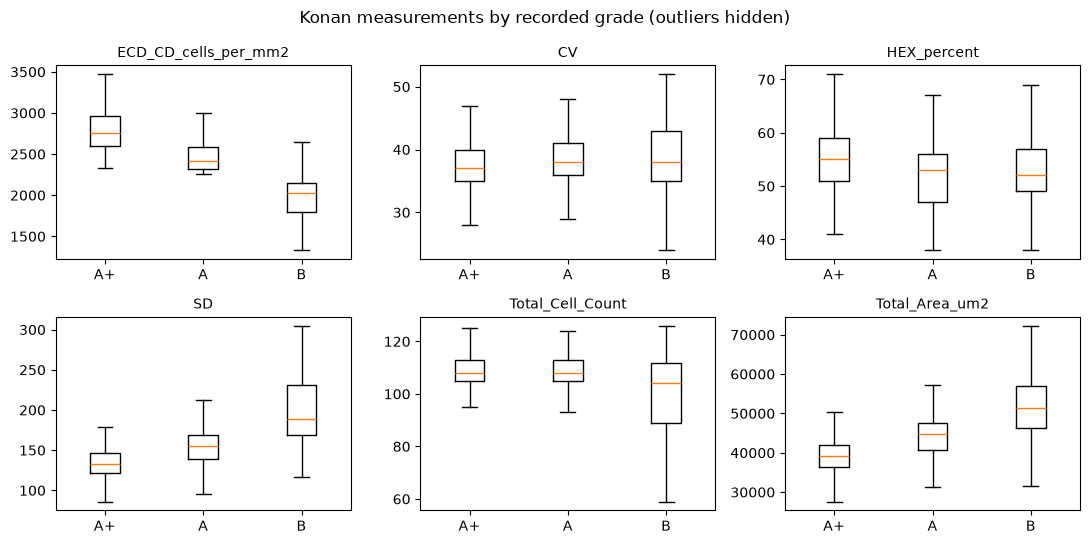

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, feature in zip(axes.flat, ms.NUMERIC_FEATURES):
    data = [labelled.loc[grades == g, feature].dropna() for g in cs.CLASSES]
    ax.boxplot(data, tick_labels=cs.CLASSES, showfliers=False)
    ax.set_title(feature, fontsize=10)
fig.suptitle("Konan measurements by recorded grade (outliers hidden)")
plt.tight_layout()
plt.show()

The six measurements are partly derived from one another: ECD is cell count ÷ area, and CV is SD ÷ mean cell area. They carry about four independent quantities, which matters when reading feature-level importance.

In [11]:
konan = labelled.dropna(subset=ms.NUMERIC_FEATURES)
ecd_from_count = konan["Total_Cell_Count"] / konan["Total_Area_um2"] * 1e6
cv_from_sd = konan["SD"] / konan["Konan_Mean_Cell_Area_um2"] * 100
print(f"Tissues with Konan values: {len(konan)}")
print(f"ECD within 1% of count / area: {(abs(ecd_from_count / konan['ECD_CD_cells_per_mm2'] - 1) < 0.01).mean():.1%}")
print(f"Correlation of CV with SD / mean cell area: r = {np.corrcoef(konan['CV'], cv_from_sd)[0, 1]:.3f}")

Tissues with Konan values: 940
ECD within 1% of count / area: 100.0%
Correlation of CV with SD / mean cell area: r = 0.998


Correlation heatmap of the Konan measurements (with donor age for context; Pearson, tissues with values recorded). ECD is strongly tied to SD (r ≈ −0.75) and total area (≈ −0.63), and CV to SD, as expected from how they are derived. Donor age is only weakly related to any of them (|r| ≤ 0.20).

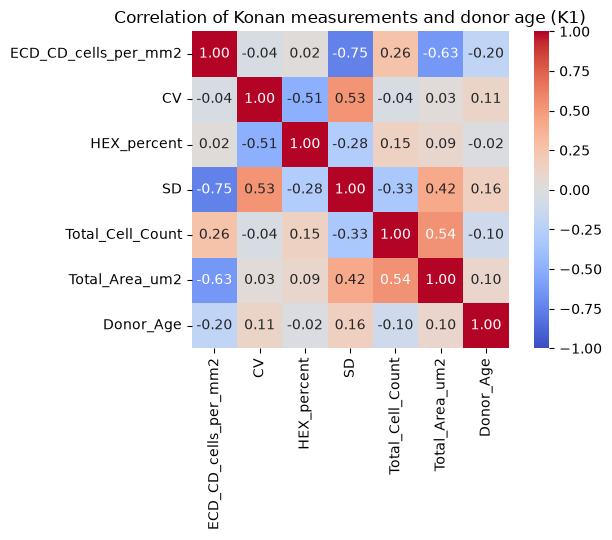

In [12]:
corr = labelled[ms.NUMERIC_FEATURES + ["Donor_Age"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation of Konan measurements and donor age (K1)")
plt.tight_layout()
plt.show()

## 4. Slit-lamp findings by grade

Prevalence among tissues where the finding was **recorded**, and the share not recorded. Stromal scar stands out (25% of recorded grade B, none of A+); most findings differ little between grades.

In [13]:
rows = {}
for feature in ms.CLINICAL_BINARY_FEATURES:
    recorded = labelled[feature].notna()
    rows[feature] = {**{f"{g} present %": 100 * labelled.loc[recorded & (grades == g), feature].eq(1).mean() for g in cs.CLASSES},
                     "Not recorded %": 100 * (~recorded).mean()}
findings = pd.DataFrame(rows).T
findings.insert(3, "B − A+", findings["B present %"] - findings["A+ present %"])
findings.round(1).sort_values("B − A+", ascending=False)

,A+ present %,A present %,B present %,B − A+,Not recorded %
Stroma_Has_Scar,0.0,6.0,25.0,25.0,44.7
Epi_Has_Haze,3.5,6.0,8.3,4.9,44.8
Endo_Has_RBC,3.5,7.0,7.6,4.1,45.8
Endo_Has_Cell_Dropout,15.2,17.1,17.7,2.5,45.8
Epi_Has_Arcus,52.8,64.0,54.8,2.0,44.8
Epi_Has_Exposure,50.3,59.5,51.2,0.8,44.8
Epi_Has_Defect,0.7,0.5,1.2,0.5,44.8
Stroma_Has_Arcus,82.0,84.5,82.1,0.1,44.7
Stroma_Has_Edema,1.7,2.0,1.2,-0.5,44.7
Descemet_Has_Folds,99.3,98.4,98.7,-0.6,48.9


Correlation heatmap of the 13 binary slit-lamp findings (Pearson on 0/1 values; a missing finding stays missing, so each pair uses tissues where both were recorded). Almost all pairs have |r| < 0.2 (the strongest is compact stroma with epithelial arcus, r ≈ 0.36), so the findings carry largely separate information.

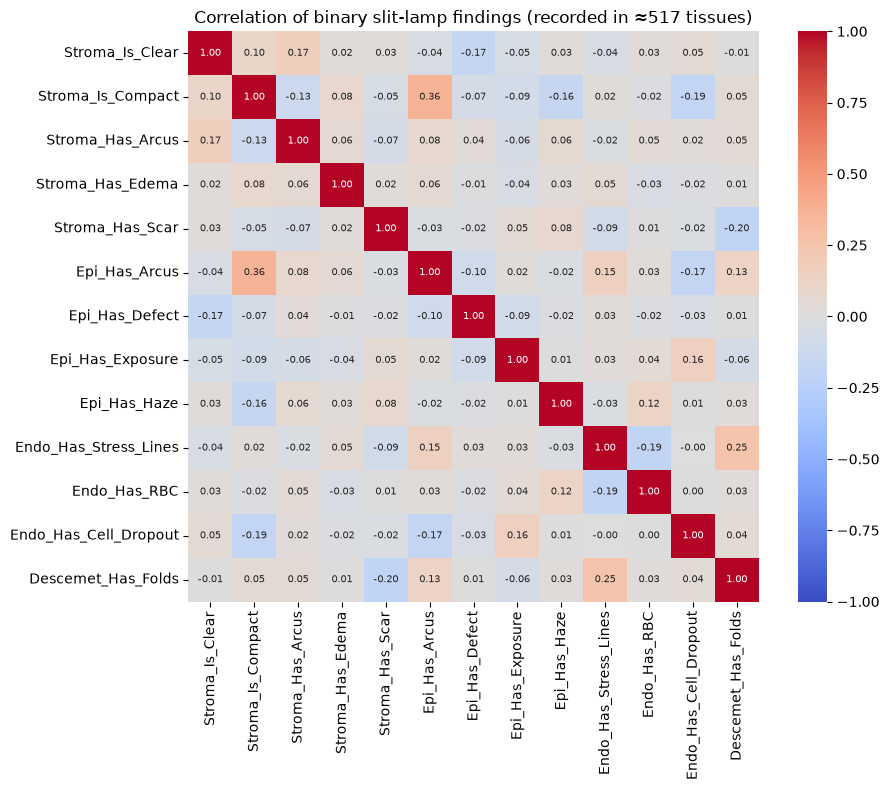

In [14]:
binary = labelled[ms.CLINICAL_BINARY_FEATURES].apply(pd.to_numeric, errors="coerce")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(binary.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            annot_kws={"size": 7}, ax=ax)
ax.set_title(f"Correlation of binary slit-lamp findings (recorded in ≈{binary.notna().all(axis=1).sum()} tissues)")
plt.tight_layout()
plt.show()

## 5. Missing information by year

Missingness is not spread evenly: slit-lamp findings are absent for every 2023 tissue (year from `Tissue_ID`). This drives the cohort decision in Hybrid 03.

In [15]:
pd.DataFrame({
    "Tissues": labelled.groupby("Year").size(),
    "Slit-lamp missing %": labelled.groupby("Year").apply(lambda d: d[ms.CLINICAL_FEATURES].isna().all(axis=1).mean() * 100),
    "Konan missing %": labelled.groupby("Year").apply(lambda d: d[ms.NUMERIC_FEATURES].isna().all(axis=1).mean() * 100),
}).round(1)

,Tissues,Slit-lamp missing %,Konan missing %
Year,,,
2020,135,0.0,40.7
2021,13,0.0,7.7
2022,62,0.0,8.1
2023,463,100.0,0.9
2024,174,0.0,9.2
2025,189,0.0,7.9


## 6. The ECD grading rule

The eye bank's ECD rule:

| ECD (cells/mm²) | Grade by ECD alone |
|---|---|
| below 2250 | **B** |
| 2250 to below 2500 | **A** |
| 2500 and above | **A+** |

Notebook 03 tested a different, **wrong** rule (B 2000–2500, A 2500–3000, A+ above 3000; ECD below 2000 not graded). Apply both to every labelled tissue with ECD and count how often each matches the recorded grade.

In [16]:
def correct_rule(ecd):
    return np.where(ecd >= 2500, "A+", np.where(ecd >= 2250, "A", "B"))


def notebook03_rule(ecd):  # the wrong rule from notebook 03; ECD below 2000 gets no grade
    return np.where(ecd > 3000, "A+", np.where(ecd >= 2500, "A", np.where(ecd >= 2000, "B", "none")))


with_ecd = labelled[labelled[cs.ECD].notna()]
ecd_values, recorded = with_ecd[cs.ECD].to_numpy(), with_ecd[ms.TARGET].to_numpy()
assert (correct_rule(ecd_values) == cs.ecd_rule(ecd_values)).all()  # the same rule as all later notebooks
pd.DataFrame({
    rule_name: {"Matches recorded grade": f"{(pred == recorded).mean():.1%}",
                **{f"Recorded {g} matched": f"{(pred[recorded == g] == g).sum()} of {(recorded == g).sum()} ({(pred[recorded == g] == g).mean():.1%})"
                   for g in cs.CLASSES}}
    for rule_name, pred in [("Notebook 03 rule (wrong)", notebook03_rule(ecd_values)),
                            ("Eye bank rule (2250 / 2500)", correct_rule(ecd_values))]
}).T

,Matches recorded grade,Recorded A+ matched,Recorded A matched,Recorded B matched
Notebook 03 rule (wrong),28.4%,106 of 505 (21.0%),75 of 281 (26.7%),86 of 154 (55.8%)
Eye bank rule (2250 / 2500),87.7%,503 of 505 (99.6%),181 of 281 (64.4%),140 of 154 (90.9%)


Recorded grade against the grade the eye bank's rule gives from ECD alone (all labelled tissues with ECD). The diagonal is agreement; tissues **below** the diagonal were graded lower than their ECD alone would give.

In [17]:
pd.crosstab(pd.Series(recorded, name="Recorded grade"), pd.Series(correct_rule(ecd_values), name="Grade from ECD rule"))[cs.CLASSES].reindex(cs.CLASSES)

Grade from ECD rule,A+,A,B
Recorded grade,,,
A+,503,2,0
A,100,181,0
B,6,8,140


The same picture as a plot, split by year: in 2023 the recorded grades follow the rule almost exactly; in other years more tissues sit off their ECD band (mostly graded lower).

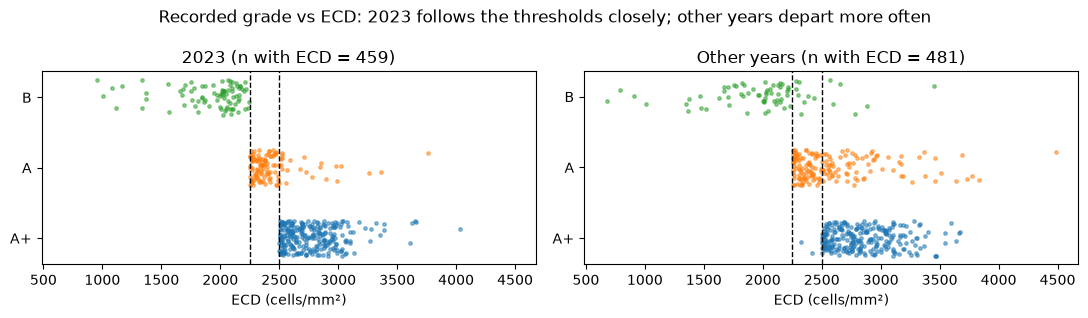

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
rng = np.random.default_rng(0)
for ax, (title, mask) in zip(axes, [("2023", labelled["Year"] == 2023), ("Other years", labelled["Year"] != 2023)]):
    for i, g in enumerate(cs.CLASSES):
        values = labelled.loc[mask.fillna(False) & (grades == g), cs.ECD].dropna()
        ax.scatter(values, np.full(len(values), i) + rng.uniform(-0.25, 0.25, len(values)), s=6, alpha=0.5)
    for cut in (2250, 2500):
        ax.axvline(cut, color="black", ls="--", lw=1)
    ax.set(title=f"{title} (n with ECD = {labelled.loc[mask.fillna(False), cs.ECD].notna().sum()})", yticks=range(3),
           yticklabels=cs.CLASSES, xlabel="ECD (cells/mm²)")
fig.suptitle("Recorded grade vs ECD: 2023 follows the thresholds closely; other years depart more often")
plt.tight_layout()
plt.show()

## Interpretation

- ECD is the dominant single signal, and the recorded grades follow the eye bank's rule (B below 2250, A from 2250, A+ from 2500) for most tissues. In 2023 they follow it almost exactly; in other years many tissues are graded below what their ECD alone would give.
- Notebook 03's early rule (2000 / 2500 / 3000) was wrong and is not used anywhere else; every later notebook uses the 2250 / 2500 rule (`cleaned_setup.ecd_rule`).
- These departures are what a model "beyond ECD" would have to explain, using the other morphology measurements, slit-lamp findings or the image. Hybrid 04 tests whether any model does better than a fitted two-threshold ECD tree; Hybrid 05 asks what the departures are associated with.

**Limitations:** descriptive only. The analysis documents (`RESULTS.md`, notebooks 08–11) record that no written copy of the eye bank's criteria was available, so the rule was reported without tests and the tested ECD baseline is a tree fitted in the training folds (it learns ≈2232 / ≈2497, Hybrid 04). Cite the source of the rule in the viva. The 2023 pattern does not show why grades were assigned that way. The quantified agreement by year (95% in 2023 vs 72–84% in other years) is computed on the image cohort in Hybrid 03.